In [1]:
import VTKData
from pathlib import Path


ROOT = Path.cwd()

VTK_PATH = ROOT / 'carCentrePlane.vtk'
# VTK_PATH = CASE / 'postProcessing/cutPlane/500/carCentrePlane.vtk'

data = VTKData.VTKData(VTK_PATH)
data.read()

pointsX = data.points[:,0]
pointsY = data.points[:,1]
pointsZ = data.points[:,2]

U = data.fields["U"]

#p = data.fields["p"]
#nut = data.fields["nut"]
#k = data.fields["k"]
#omega = data.fields["omega"]

Ux = U[:,0]
Uy = U[:,1]
Uz = U[:,2]
Umag = (Uy ** 2 + Uz ** 2) ** 0.5

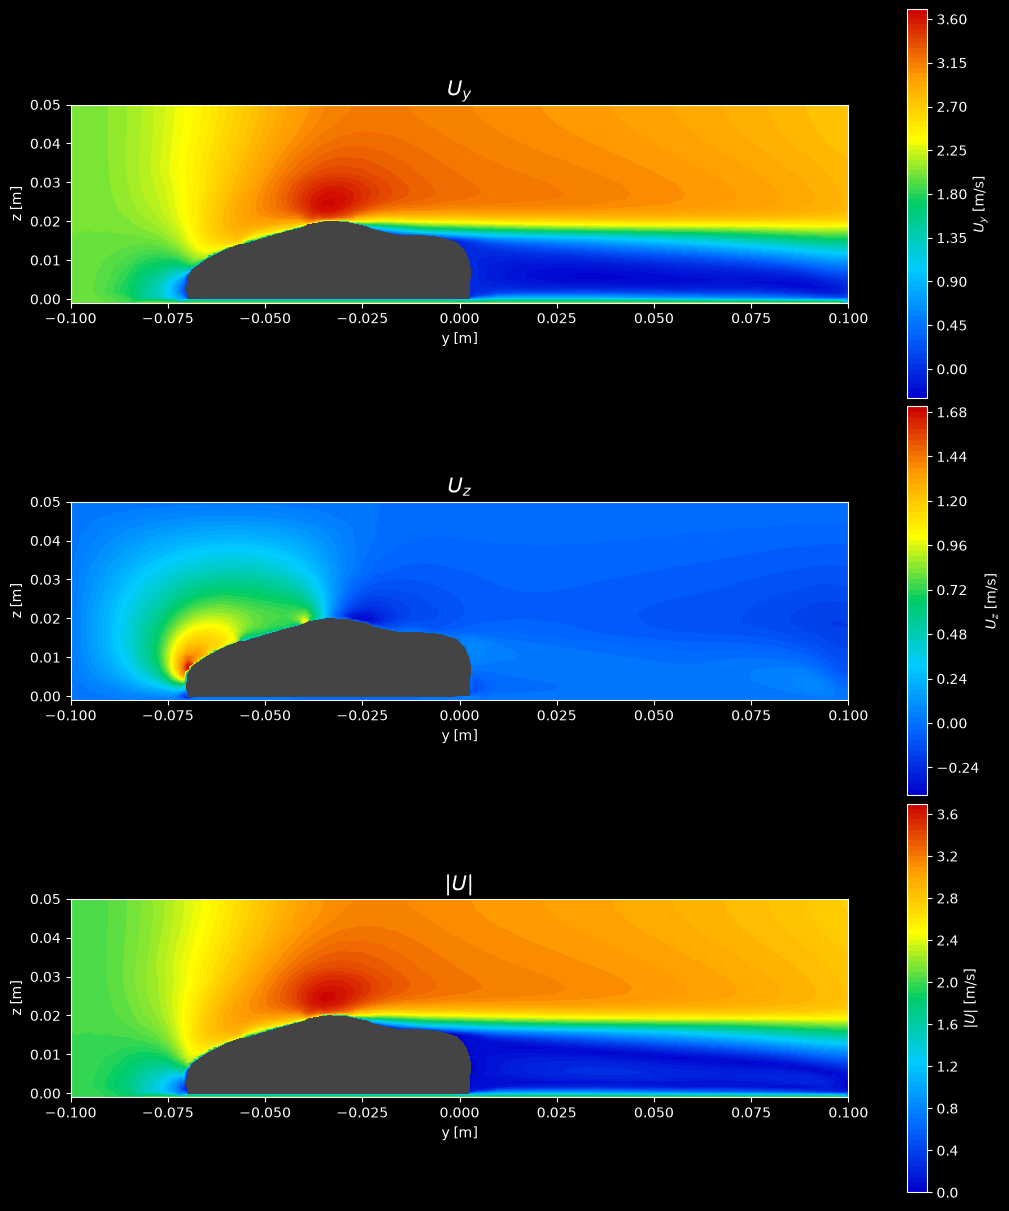

In [2]:
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import matplotlib.tri as tri


triangulation = tri.Triangulation(pointsY, pointsZ)

paraview_cmap = LinearSegmentedColormap.from_list(
    "paraview",
    [
        "#0000cc",
        "#0066ff",
        "#00ccff",
        "#00cc66",
        "#ffff00",
        "#ff9900",
        "#cc0000"
    ],
    N=256
)

fields = [
    (Uy, r"$U_y$", r"$U_y$ [m/s]"),
    (Uz, r"$U_z$", r"$U_z$ [m/s]"),
    (Umag, r"$|U|$", r"$|U|$ [m/s]")
]

fig, axes = plt.subplots(3, 1, figsize=(10, 12), constrained_layout=True)

for ax, (values, title, cbar_label) in zip(axes, fields):

    contour = ax.tricontourf(
        triangulation,
        values,
        levels=80,
        cmap=paraview_cmap
    )

    ax.tricontourf(
        triangulation,
        Umag,
        levels=[-1, 1e-8],
        colors=["#444444"]
    )

    ax.set_title(title, fontsize=15)

    ax.set_xlabel("y [m]")
    ax.set_ylabel("z [m]")
    ax.set_aspect("equal", adjustable="box")

    cbar = fig.colorbar(contour, ax=ax)
    cbar.set_label(cbar_label)

plt.show()

In [3]:
import numpy as np
import torch

from normalizer import Normalizer, Mode
from pinn import PINN
from train import train

torch.manual_seed(42)

EPOCHS = 2000
CONTINUITY_WEIGHT = 1e-4
MOMENTUM_WEIGHT = 1e-6

yz = torch.tensor(data.points[:, [1, 2]], dtype=torch.float32)
velocity = torch.tensor(U[:, [1, 2]], dtype=torch.float32)
pressure = torch.tensor(data.fields['p'].reshape(-1, 1), dtype=torch.float32)
nut = torch.tensor(data.fields['nut'].reshape(-1), dtype=torch.float32)
targets_physical = torch.cat([velocity, pressure], dim=1)

normalizer = Normalizer()
normalizer.normalize('coordinates', yz, Mode.MIN_MAX)
targets_normalized = normalizer.normalize('fields', targets_physical, Mode.MAX_ABS)

network = PINN(
    n_input=2,
    n_output=3,
    n_hidden=64,
    n_hidden_layers=3,
    normalizer=normalizer,
)
optimizer = torch.optim.Adam(network.parameters(), lr=1e-3)

history = train(
    network=network,
    optimizer=optimizer,
    epochs=EPOCHS,
    continuity_weight=CONTINUITY_WEIGHT,
    momentum_weight=MOMENTUM_WEIGHT,
    yz=yz,
    nut=nut,
    targets_normalized=targets_normalized,
)

   1 | data=0.291647 | total=0.293108
 100 | data=0.041712 | total=0.042272
 200 | data=0.027872 | total=0.029669
 300 | data=0.018851 | total=0.020866
 400 | data=0.013201 | total=0.014938
 500 | data=0.010403 | total=0.011752
 600 | data=0.009367 | total=0.010484
 700 | data=0.008766 | total=0.009696
 800 | data=0.008345 | total=0.009160
 900 | data=0.007998 | total=0.008741
1000 | data=0.007706 | total=0.008406
1100 | data=0.007413 | total=0.008088
1200 | data=0.007107 | total=0.007773
1300 | data=0.006763 | total=0.007424
1400 | data=0.006414 | total=0.007076
1500 | data=0.006024 | total=0.006690
1600 | data=0.005703 | total=0.006382
1700 | data=0.005411 | total=0.006109
1800 | data=0.005201 | total=0.005928
1900 | data=0.004938 | total=0.005627
2000 | data=0.004709 | total=0.005382


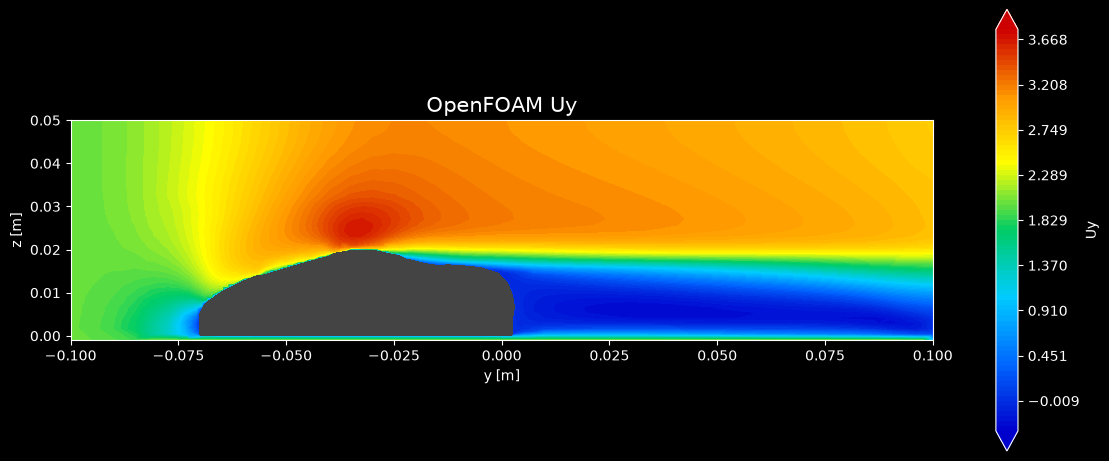

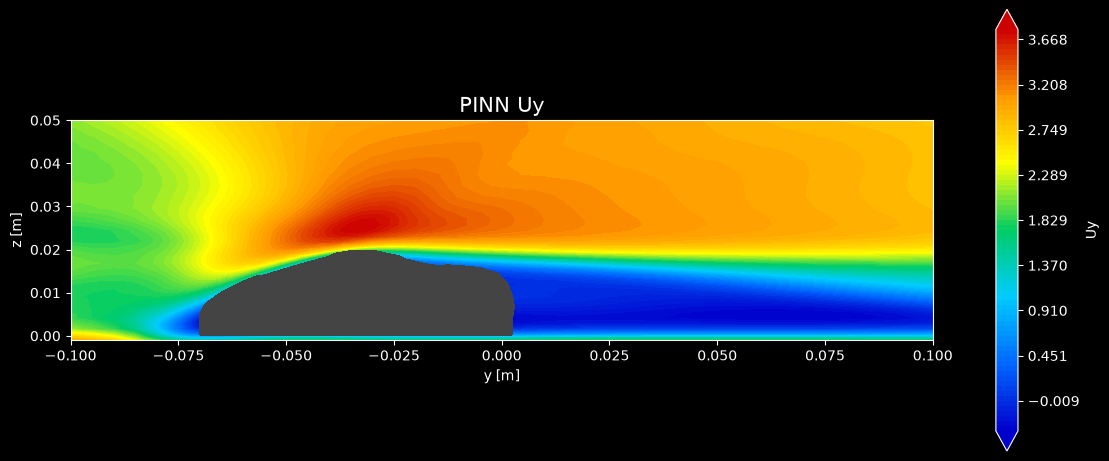

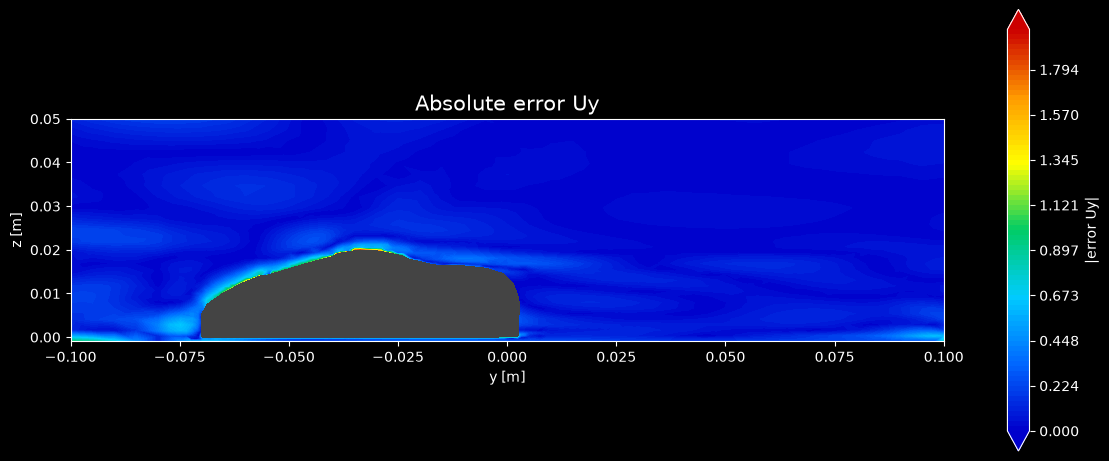

RMSE Uy: 0.302167


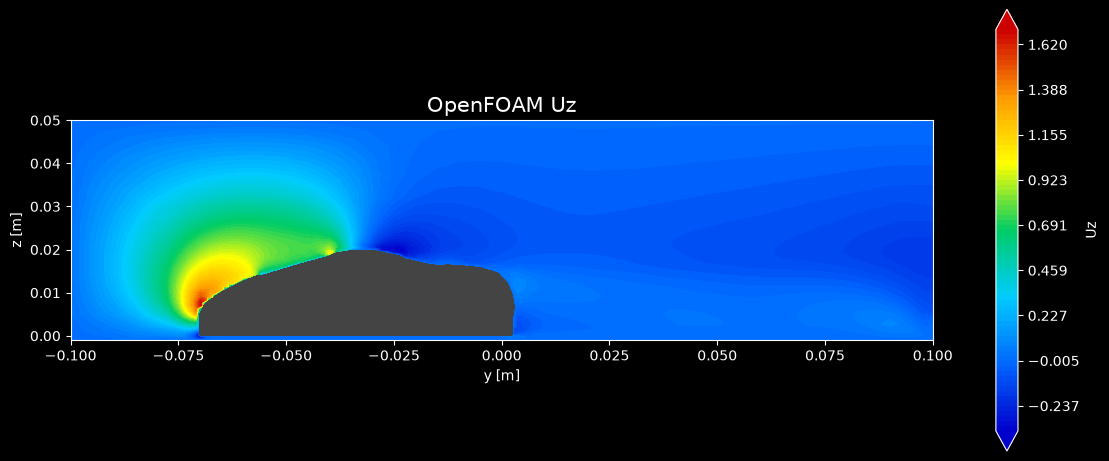

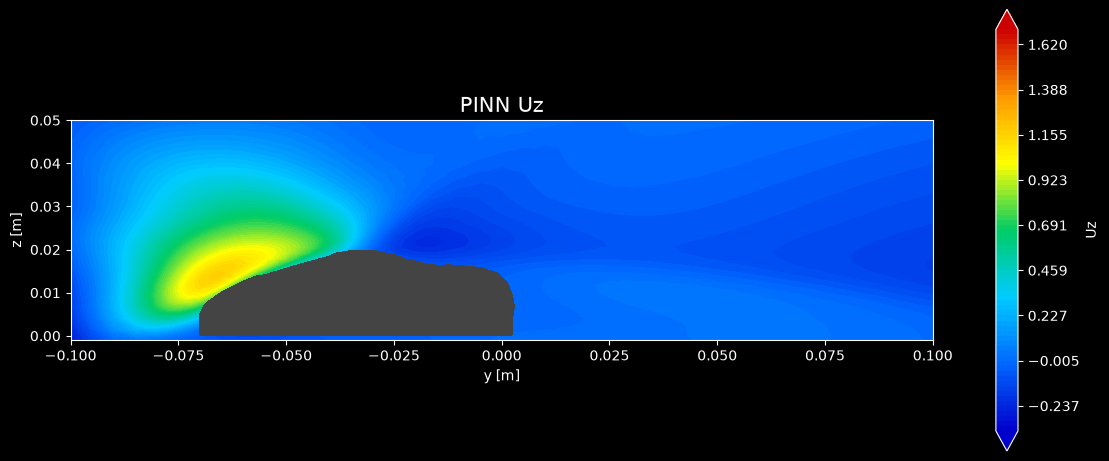

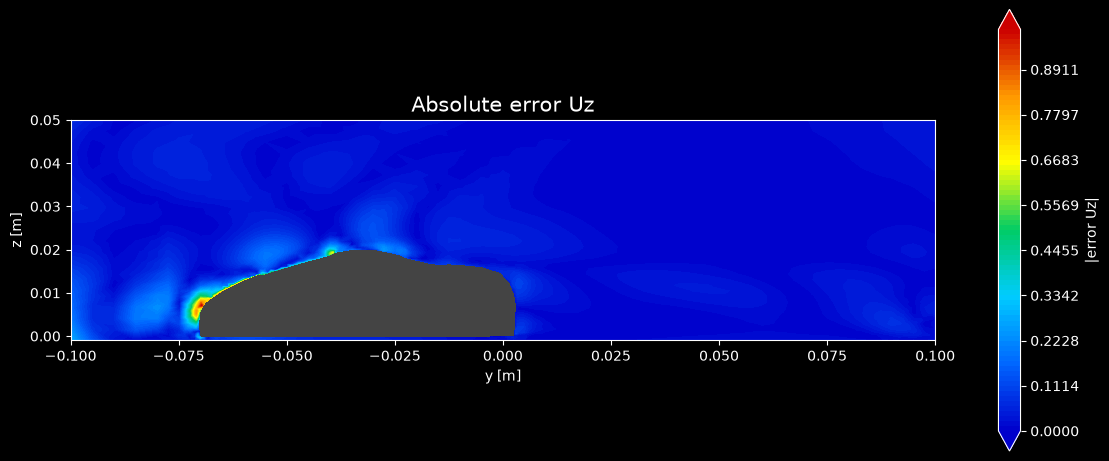

RMSE Uz: 0.119143


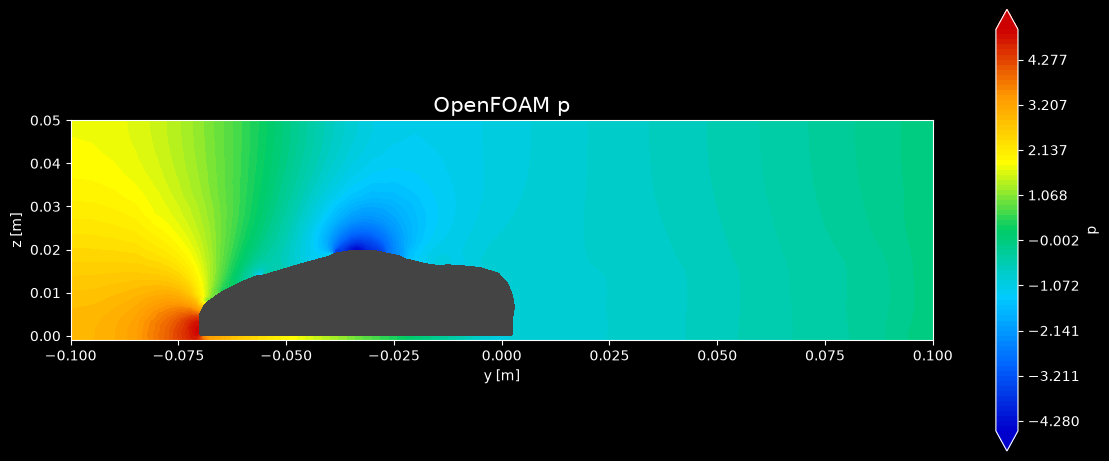

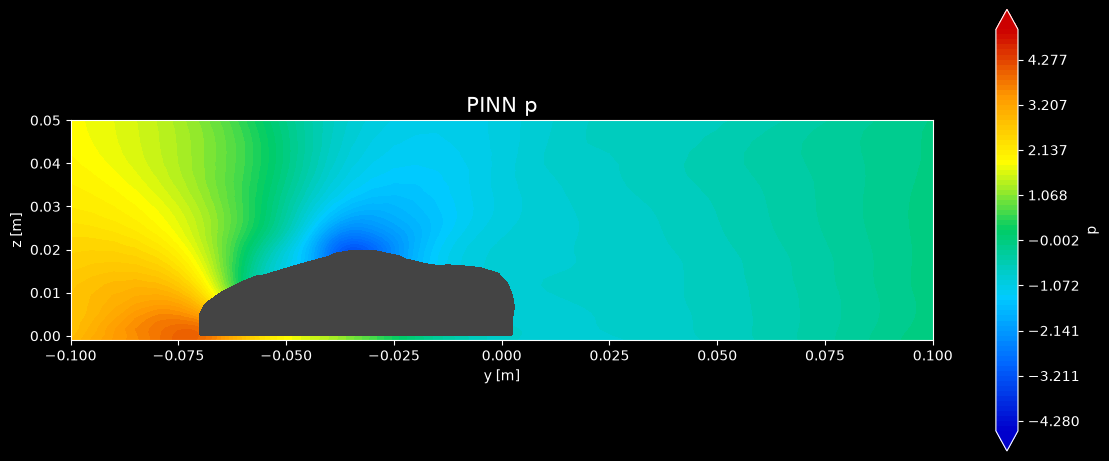

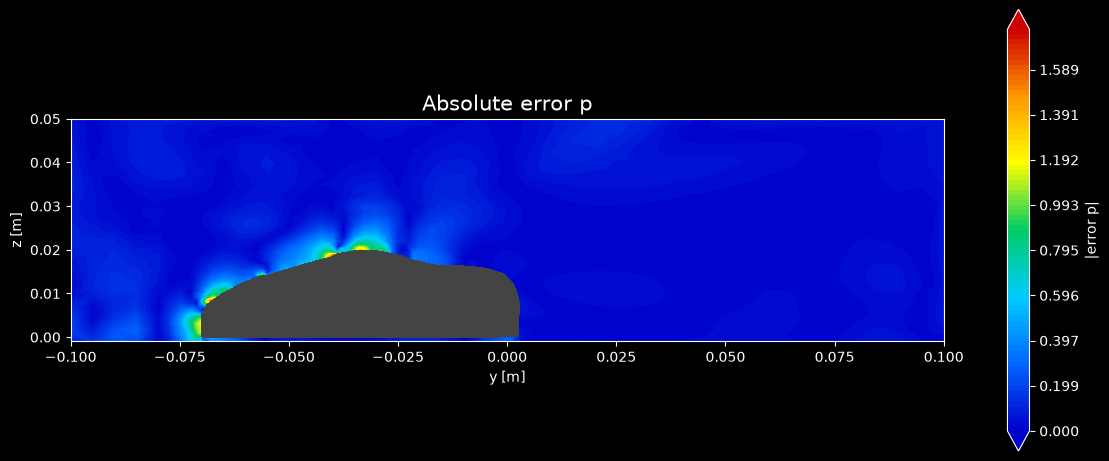

RMSE p: 0.242871


In [5]:
network.eval()
with torch.no_grad():
    prediction = network.predict_physical(yz).cpu().numpy()

coordinates = yz.cpu().numpy()
truth = targets_physical.cpu().numpy()
field_names = ('Uy', 'Uz', 'p')

triangulation = tri.Triangulation(coordinates[:, 0], coordinates[:, 1])
body_mask = np.sqrt(truth[:, 0] ** 2 + truth[:, 1] ** 2)

for field_index, field_name in enumerate(field_names):
    exact = truth[:, field_index]
    predicted = prediction[:, field_index]
    error = np.abs(predicted - exact)

    value_min = min(exact.min(), predicted.min())
    value_max = max(exact.max(), predicted.max())
    common_levels = np.linspace(value_min, value_max, 81)
    error_levels = np.linspace(0.0, max(error.max(), 1e-12), 81)

    panels = (
        (exact, f'OpenFOAM {field_name}', common_levels, field_name),
        (predicted, f'PINN {field_name}', common_levels, field_name),
        (error, f'Absolute error {field_name}', error_levels, f'|error {field_name}|'))

    for values, title, levels, colorbar_label in panels:
        fig, ax = plt.subplots(figsize=(11, 4.5), constrained_layout=True)
        contour = ax.tricontourf(triangulation, values, levels=levels, cmap=paraview_cmap, extend='both')

        ax.tricontourf( triangulation, body_mask, levels=[-1.0, 1e-8], colors=['#444444'] )

        ax.set_title(title, fontsize=15)
        ax.set_xlabel('y [m]')
        ax.set_ylabel('z [m]')
        ax.set_aspect('equal', adjustable='box')
        colorbar = fig.colorbar(contour, ax=ax)
        colorbar.set_label(colorbar_label)
        plt.show()

    rmse = np.sqrt(np.mean((predicted - exact) ** 2))
    print(f'RMSE {field_name}: {rmse:.6g}')